Se crean las anotaciones de no TEJIDO NO ETIQUETADO (no_labeled) y las de FONDO (background)

# Crear Anotaciones con clase 'no_labeled'

Este notebook:
1. Detecta tejido usando HSV thresholding
2. Encuentra áreas de tejido NO anotadas
3. Crea polígonos para esas áreas con clase 'no_labeled'
4. Crea polígonos para fondo
4. Guarda las anotaciones corregidas

In [140]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape, Polygon, MultiPolygon, mapping
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm

In [141]:
DATA = Path("../../data")
DATA_DIR = DATA / "raw"
WSI_DIR = DATA_DIR / "wsi_images"
ANNOT_DIR = DATA_DIR / "annotations_resized"
OUTPUT_DIR = DATA_DIR / "annot_cleanned_test"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

In [ ]:
#mask_to_polygons viejo

def mask_to_polygons_old(mask, min_area=1000):
    """Convierte máscara binaria a polígonos."""
    contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    
    polygons = []
    for contour in contours:
        if cv2.contourArea(contour) < min_area:
            continue
        contour = contour.squeeze()
        if len(contour.shape) == 1:
            continue
        coords = [(float(x), float(y)) for x, y in contour]
        if len(coords) >= 3:
            polygons.append(Polygon(coords))
    
    return polygons

In [142]:
def mask_to_polygons(mask, min_area=1000):
    contours, hierarchy = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    print('hierachy: ',hierarchy)
    if hierarchy is None:
        return []
    
    polygons = []
    hierarchy = hierarchy[0]
    print(f"Num contours {len(contours)}, min area: {min_area}")
    for i, h in enumerate(hierarchy[:5]):
        if h[3] == -1:
            area = cv2.contourArea(contours[i])
            print(f"  [{i}] h={h}, area={area}")

    for i, h in enumerate(hierarchy):
        if h[3] > 0:
            ext_contour = contours[i].squeeze()
            if len(ext_contour) < 4:
                continue
            if len(ext_contour.shape) == 1:
                continue
            if cv2.contourArea(contours[i]) < min_area:
                continue
            
            ext_coords = [(float(x), float(y)) for x, y in ext_contour]
            
            interior_coords_list = []
            for j, h2 in enumerate(hierarchy):
                if h2[3] == i:
                    hole_contour = contours[j].squeeze()
                    if len(hole_contour.shape) == 1:
                        continue
                    interior_coords_list.append([(float(x), float(y)) for x, y in hole_contour])
                if len(hole_contour) < 4:
                    continue
            
            if len(interior_coords_list) > 0:
                poly = Polygon(ext_coords, interior_coords_list)
            else:
                poly = Polygon(ext_coords)
            
            if poly.is_valid and len(ext_coords) >= 3:
                polygons.append(poly)
    print('poly in mask_to_polygons: ',polygons)
    return polygons

def detect_background_hsv(image, sat_threshold=30, value_threshold=200):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lower_white = np.array([0, 0, value_threshold])
    upper_white = np.array([180, sat_threshold, 255])
    mask = cv2.inRange(hsv, lower_white, upper_white)
    return mask

def rasterize_class(annotations, img_shape, class_name):
    """Rasteriza solo una clase específica de las anotaciones."""
    h, w = img_shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    
    for feature in annotations['features']:
        if feature['properties'].get('name') != class_name:
            continue
        
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(mask, [ext_coords], 255)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(mask, [int_coords], 0)
    
    return mask
def rasterize_annotations(annotations, img_shape):
    h, w = img_shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    
    for feature in annotations['features']:
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(mask, [ext_coords], 255)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(mask, [int_coords], 0)
    
    return mask

def visualize_cleaning(img_rgb, original_mask, error_mask, clean_mask, class_name):
    """Visualiza el proceso de limpieza de una clase."""
    fig, axes = plt.subplots(1, 3, figsize=(20, 10))
    
    axes[0].imshow(img_rgb)
    axes[0].set_title('Imagen Original')
    axes[0].imshow(original_mask,cmap= 'gray', alpha = 0.5)
    axes[0].axis('off')
    
    axes[1].imshow(img_rgb)
    axes[1].imshow(clean_mask, cmap='gray',alpha = 0.5)
    axes[1].set_title(f'{class_name} - Limpiado')
    axes[1].axis('off')
    
    axes[2].imshow(img_rgb)
    axes[2].imshow(error_mask, cmap='gray',alpha = 0.5)
    axes[2].set_title(f'{class_name} - Limpiado')
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()
    
def visualize_annotations(img_rgb, annotations, alpha=0.25):
    colors = {
        'Decidua': (255, 0, 0),
        'Labyrinth': (0, 255, 0),
        'Junctional Zone': (0, 0, 255),
        'no_labeled': (255, 255, 0),
        'background': (128, 128, 128)
    }
    
    overlay = img_rgb.copy()
    
    # Separar tissue de background
    tissue_features = [f for f in annotations['features'] if f['properties'].get('name') != 'background']
    print(tissue_features)
    # Dibujar tissue primero
    for feature in tissue_features:
        geom = shape(feature['geometry'])
        class_name = feature['properties'].get('name', 'unknown')
        color = colors.get(class_name, (128, 128, 128))
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(overlay, [ext_coords], color)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(overlay, [int_coords], (0, 0, 0))

    
    result = cv2.addWeighted(img_rgb, 1 - alpha, overlay, alpha, 0)

    plt.figure(figsize=(15, 12))
    plt.imshow(result)
    plt.title('Anotaciones Superpuestas')
    plt.axis('off')
    
    legend_elements = [plt.Rectangle((0, 0), 1, 1, facecolor=np.array(c)/255) 
                       for c in colors.values()]
    plt.legend(legend_elements, colors.keys(), loc='upper right')
    plt.show()

def clean_tissue_annotations(annotations, img, class_name, sat_threshold=30, value_threshold=200, min_error_area=100):
    """
    Limpia las anotaciones de una clase tissue removiendo áreas de fondo incorrectamente anotadas.
    """
    # 1. Obtener máscara de la clase
    class_mask = rasterize_class(annotations, img.shape, class_name)
    
    # 2. Obtener máscara de fondo
    background_mask = detect_background_hsv(img, sat_threshold, value_threshold)

    # 3. Encontrar intersección = áreas de error
    error_mask = cv2.bitwise_and(class_mask, background_mask)
    
    # 4. Aplicar morphología para reducir ruido
    if min_error_area > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(12,12))
        error_mask = cv2.erode(error_mask,kernel,iterations = 2)
        error_mask = cv2.dilate(error_mask,kernel,iterations = 2)
    
    # 5. Crear máscara limpia
    clean_mask = cv2.bitwise_and(class_mask, cv2.bitwise_not(error_mask))
    
    # 6. Convertir a polígonos
    clean_polygons = mask_to_polygons(clean_mask, min_area=min_error_area)
    print('clean_poly: ',clean_polygons)
    # 7. Crear features
    if len(clean_polygons) == 1:
        geom_type = 'Polygon'
        geom_coords = [list(clean_polygons[0].exterior.coords)[:-1]]
    else:
        geom_type = 'MultiPolygon'
        geom_coords = [[list(poly.exterior.coords)[:-1] for poly in clean_polygons]]
    
    
    geom = shape({'type': geom_type,
                 'coordinates': geom_coords
                 })
    print ('geom en clean_tis_annot: ', geom)
    feature = geojson.Feature(geometry=geom,
                              properties = {'objectType': 'annotation',
                                            'name': class_name
                                            }
                            )
    
    return feature, clean_mask, error_mask

## Ejemplo con slide_001

In [112]:
slide_id = "slide_001"

img_path = WSI_DIR / f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(f"Imagen: {img.shape}")

annot_path = ANNOT_DIR / f"{slide_id}.geojson"
with open(annot_path, 'r') as f:
    annotations = geojson.load(f)

print(f"Features originales: {len(annotations['features'])}")

background_mask = detect_background_hsv(img, 30, 180)
tissue_mask = cv2.bitwise_not(background_mask)

print(f"Fondo: {np.sum(background_mask > 0) / background_mask.size * 100:.2f}%")
print(f"Tejido: {np.sum(tissue_mask > 0) / tissue_mask.size * 100:.2f}%")

Imagen: (6240, 8686, 3)
Features originales: 6
Fondo: 65.24%
Tejido: 34.76%


In [78]:
annot_mask = rasterize_annotations(annotations, img.shape)
print(f"Anotado: {np.sum(annot_mask > 0) / annot_mask.size * 100:.2f}%")

unlabeled_tissue = cv2.bitwise_and(tissue_mask, cv2.bitwise_not(annot_mask))
print(f"Tejido no anotado: {np.sum(unlabeled_tissue > 0) / unlabeled_tissue.size * 100:.2f}%")

Anotado: 32.72%
Tejido no anotado: 4.88%


In [79]:
# Generar polígonos de tejido no labeleado
unlabeled_polygons = mask_to_polygons(unlabeled_tissue, min_area=5000)
print(f"Polígonos no_labeled: {len(unlabeled_polygons)}")

no_labeled_features = []
for poly in unlabeled_polygons:
    feature = {
        "type": "Feature",
        "properties": {"name": "no_labeled", "class": "no_labeled"},
        "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
    }
    no_labeled_features.append(feature)

# Generar polígonos de background no labeleado
unlabeled_background = cv2.bitwise_and(background_mask, cv2.bitwise_not(annot_mask))
background_polygons = mask_to_polygons(unlabeled_background, min_area=10000)
print(f"Polígonos background: {len(background_polygons)}")

background_features = []
for poly in background_polygons:
    feature = {
        "type": "Feature",
        "properties": {"name": "background", "class": "background"},
        "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
    }
    background_features.append(feature)

# Combinar todas las features
all_features = annotations['features'] + no_labeled_features + background_features
new_annotations = {"type": "FeatureCollection", "features": all_features}

print(f"Originales: {len(annotations['features'])}, no_labeled: {len(no_labeled_features)}, background: {len(background_features)}, Total: {len(all_features)}")

Polígonos no_labeled: 24
Polígonos background: 2
Originales: 6, no_labeled: 24, background: 2, Total: 32


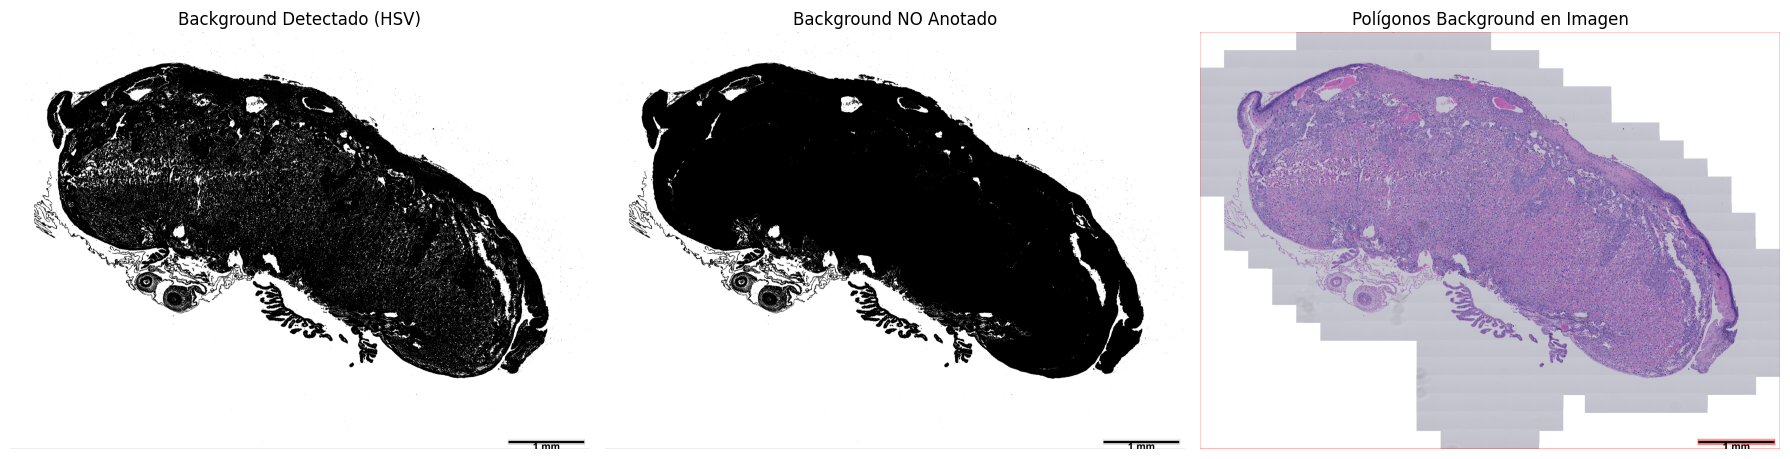

Polígonos de background generados: 2
Área total background no anotado: 62.40%


In [80]:
# Verificar polígonos de background generados
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(background_mask, cmap='gray')
axes[0].set_title('Background Detectado (HSV)')
axes[0].axis('off')

axes[1].imshow(unlabeled_background, cmap='gray')
axes[1].set_title('Background NO Anotado')
axes[1].axis('off')

# Dibujar polígonos de background sobre la imagen
overlay = img_rgb.copy()
for feature in background_features:
    geom = shape(feature['geometry'])
    coords = np.array(geom.exterior.coords, dtype=np.int32)
    cv2.polylines(overlay, [coords], True, (255, 0, 0), 3)

axes[2].imshow(overlay)
axes[2].set_title('Polígonos Background en Imagen')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Polígonos de background generados: {len(background_features)}")
print(f"Área total background no anotado: {np.sum(unlabeled_background > 0) / unlabeled_background.size * 100:.2f}%")

In [ ]:
visualize_annotations(img_rgb, new_annotations)

## Procesar todos los slides

In [143]:
def process_slide(slide_id, sat_threshold=30, value_threshold=200, min_area=5000, min_error_area=100, save = False,visualize = False):
    img_path = WSI_DIR / f"{slide_id}.tif"
    if not img_path.exists():
        print('img_path not exists')
        return None
    
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    annot_path = ANNOT_DIR / f"{slide_id}.geojson"
    if not annot_path.exists():
        print("annot_path not exists")
        return None
    
    with open(annot_path, 'r') as f:
        annotations = geojson.load(f)
    
    
    
    #Filtrado para cada clase para sacar 
    tissue_classes = ['Decidua','Labyrinth','Junctional Zone']
    all_features = []
    for class_name in tissue_classes:
        feature, clean_mask, error_mask = clean_tissue_annotations(
            annotations, img, class_name,
            sat_threshold=sat_threshold,
            value_threshold=value_threshold,
            min_error_area=min_error_area
        )
        all_features.append(feature)
        #clean_polygon = mask_to_polygons(clean_mask)
        #print(clean_polygon)
        if visualize:
            original_mask = rasterize_class(annotations, img.shape, class_name)
            visualize_cleaning(img_rgb, original_mask, error_mask, clean_mask, class_name)
    #print(all_features2)
    #return features





    #Generación de anotaciones de tejido no anotado

    background_mask = detect_background_hsv(img, sat_threshold, value_threshold)
    tissue_mask = cv2.bitwise_not(background_mask)
    annot_mask = rasterize_annotations(annotations, img.shape)
    #print(annot_mask)
    unlabeled_tissue = cv2.bitwise_and(tissue_mask, cv2.bitwise_not(annot_mask))
    
    unlabeled_polygons = mask_to_polygons(unlabeled_tissue, min_area=min_area)
    print('unlabeled_polygons: ',unlabeled_polygons)
    #print(annotations)
    no_labeled_features = []
    for poly in unlabeled_polygons:
        #feature = {
        #    "type": "Feature",
        #    "properties": {"name": "no_labeled", "class": "no_labeled"},
        #    "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
        #}
        feature = geojson.Feature(geometry = mapping(poly),
                                  properties = {'objectType': 'processed',
                                                'name': 'no_labeled'}
                                )
        no_labeled_features.append(feature)
    
    unlabeled_background = cv2.bitwise_and(background_mask, cv2.bitwise_not(annot_mask))
    #background_polygons = mask_to_polygons(unlabeled_background, min_area=min_bg_area)
    


    #all_features = annotations['features']  + no_labeled_features
    all_features = all_features + no_labeled_features
    new_annotations = {"type": "FeatureCollection", "features": all_features}
    print(type(all_features))
    if save:
        
        output_path = OUTPUT_DIR / f"{slide_id}.geojson"
        with open(output_path, 'w') as f:
            geojson.dump(new_annotations, f)
            
    if visualize:
        visualize_annotations(img_rgb,new_annotations)
    
    return {
        'annotations': new_annotations,
        'slide_id': slide_id,
        'original_features': len(annotations['features']),
        'no_labeled_features': len(no_labeled_features),
        #'background_features': len(background_features),
        'total_features': len(all_features),
        'tissue_pct': np.sum(tissue_mask > 0) / tissue_mask.size * 100,
        'unlabeled_pct': np.sum(unlabeled_tissue > 0) / unlabeled_tissue.size * 100,
        'background_not_annotated_pct': np.sum(unlabeled_background > 0) / unlabeled_background.size * 100
    }
    
   

In [144]:
annot_files = sorted(ANNOT_DIR.glob("slide_*.geojson"))
slide_ids = [f.stem for f in annot_files]
SAT_THRESHOLD = 30
VALUE_THRESHOLD = 120
geojson.geometry.DEFAULT_PRECISION = 12
print(f"Procesando {len(slide_ids)} slides...")

results = []
for slide_id in tqdm(slide_ids[:1]):
    #try:
        print(slide_id)
        result = process_slide(slide_id, SAT_THRESHOLD, VALUE_THRESHOLD,save =  True,visualize=False,min_error_area=20)
        #print('res: ', result)
        #if result:
        #    results.append(result)
    #except Exception as e:
    #    print(f"Error {slide_id}: {e}")

Procesando 50 slides...


  0%|          | 0/1 [00:00<?, ?it/s]

slide_001


  0%|          | 0/1 [00:01<?, ?it/s]

hierachy:  [[[ 1 -1 -1 -1]
  [ 2  0 -1 -1]
  [ 3  1 -1 -1]
  [ 4  2 -1 -1]
  [ 5  3 -1 -1]
  [ 6  4 -1 -1]
  [ 7  5 -1 -1]
  [ 8  6 -1 -1]
  [ 9  7 -1 -1]
  [10  8 -1 -1]
  [11  9 -1 -1]
  [12 10 -1 -1]
  [13 11 -1 -1]
  [14 12 -1 -1]
  [15 13 -1 -1]
  [16 14 -1 -1]
  [17 15 -1 -1]
  [18 16 -1 -1]
  [19 17 -1 -1]
  [20 18 -1 -1]
  [21 19 -1 -1]
  [22 20 -1 -1]
  [23 21 -1 -1]
  [24 22 -1 -1]
  [25 23 -1 -1]
  [26 24 -1 -1]
  [27 25 -1 -1]
  [28 26 -1 -1]
  [29 27 -1 -1]
  [-1 28 30 -1]
  [31 -1 -1 29]
  [32 30 -1 29]
  [33 31 -1 29]
  [34 32 -1 29]
  [35 33 -1 29]
  [36 34 -1 29]
  [37 35 -1 29]
  [38 36 -1 29]
  [39 37 -1 29]
  [40 38 -1 29]
  [41 39 -1 29]
  [42 40 -1 29]
  [43 41 -1 29]
  [44 42 -1 29]
  [45 43 -1 29]
  [46 44 -1 29]
  [47 45 -1 29]
  [48 46 -1 29]
  [49 47 -1 29]
  [50 48 -1 29]
  [51 49 -1 29]
  [52 50 -1 29]
  [53 51 -1 29]
  [54 52 -1 29]
  [55 53 -1 29]
  [56 54 -1 29]
  [57 55 -1 29]
  [58 56 -1 29]
  [59 57 -1 29]
  [60 58 -1 29]
  [61 59 -1 29]
  [62 60 -1 2

UnboundLocalError: local variable 'hole_contour' referenced before assignment

# Visualize annotations

In [ ]:
from glob import glob

annots_paths = sorted(glob('/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annot_cleanned/*.geojson'))

#print(annots_paths)
for annot_path in annots_paths:
    slide_id = annot_path.split('/')[-1].split('.')[0]
    img_path = WSI_DIR / f"{slide_id}.tif"
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    
    print(annot_path)
    with open(annot_path, 'r') as f:
        annotations = geojson.load(f)
    visualize_annotations(img_rgb, annotations)

In [60]:
slide_id = "slide_001"

img_path = WSI_DIR / f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

annot_path = OUTPUT_DIR / f"{slide_id}.geojson"
with open(annot_path, 'r') as f:
    annotations = geojson.load(f)
    print(annotations[0])


{"geometry": {"coordinates": [[[[5827.887262, 2040.996256], [5826.832292, 2040.441272], [5823.0874, 2037.466358], [5822.942404, 2037.361361], [5818.332537, 2036.263892], [5813.332681, 2035.191423], [5807.517848, 2032.506501], [5803.832954, 2030.941546], [5795.083206, 2024.691725], [5791.8333, 2021.906806], [5789.333372, 2020.691841], [5785.880971, 2018.546902], [5782.833559, 2016.941948], [5781.151107, 2015.604487], [5780.083638, 2014.942006], [5779.048668, 2014.004533], [5773.083839, 2012.442078], [5769.811434, 2011.189614], [5768.083983, 2010.942121], [5766.134039, 2010.64213], [5764.584084, 2012.192085], [5764.584084, 2014.44202], [5760.334206, 2018.441905], [5760.334206, 2018.691898], [5760.084214, 2018.941891], [5760.084214, 2029.691582], [5758.334264, 2031.691524], [5758.084271, 2031.691524], [5758.084271, 2031.941517], [5757.834278, 2032.19151], [5757.834278, 2036.941373], [5758.084271, 2037.191366], [5758.084271, 2037.441358], [5758.334264, 2037.441358], [5767.084012, 2046.1911

In [63]:
coords = annotations[0].get('geometry').get('coordinates')

In [66]:
coords[0][0][0]

[5827.887262, 2040.996256]